# Rajuk Image Level Classifier — CNN

**Pipeline:**
1. Mount Drive & Import Libraries
2. Load Labels
3. Collect Image Paths
4. Visualise Sample Images *(data preview)*
5. Build Dataset & 3-Way Split (Train / Validation / Test)
6. Define CNN Architecture
7. Train with K-Fold Cross-Validation
8. Evaluate on Test Set — Confusion Matrix & Report
9. Learning Curves (Train / Val / Test error by dataset size)
10. Save Model

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import Libraries

In [2]:
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset, TensorDataset

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 3. Configuration

In [3]:
# ── Paths ─────────────────────────────────────────────────────────────────────
DRIVE_BASE    = Path('/content/drive/MyDrive/ML_Project')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet - Sheet1.csv'

# ── Hyper-parameters ──────────────────────────────────────────────────────────
CLASS_NAMES   = ['negative', 'moderate', 'positive']
ALLOWED_EXTS  = {'.jpg', '.jpeg', '.png', '.bmp'}
IMAGE_SIZE    = (128, 128)   # (H, W)
BATCH_SIZE    = 32
LR            = 0.001
NUM_EPOCHS    = 15           # per fold
KFOLD_SPLITS  = 5
PATIENCE      = 5            # early-stopping patience

# ── Dataset-size steps for learning-curve plot ────────────────────────────────
# We will evaluate train / val / TEST error at each of these subset sizes.
DATASET_STEPS = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

print('Configuration loaded.')

Configuration loaded.


## 4. Load Labels from Excel / CSV

In [4]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(df, target_normalized):
    for col in df.columns:
        if normalize_header(col) == target_normalized:
            return col
    return None

def normalize_level(value):
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    mapping = {'p': 'positive', 'positive': 'positive',
               'm': 'moderate', 'moderate': 'moderate',
               'n': 'negative', 'negative': 'negative'}
    return mapping.get(text)

def load_label_mapping(df, level_col, class_names):
    label_lookup = {name: idx for idx, name in enumerate(class_names)}
    label_map = {}
    for row_index, value in enumerate(df[level_col].tolist(), start=1):
        normalized = normalize_level(value)
        if normalized is None:
            continue
        label_map[row_index] = label_lookup[normalized]
    return label_map

# ── Load spreadsheet ──────────────────────────────────────────────────────────
if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(
        f'No dataset file found at {DRIVE_BASE}. '
        'Expected Rajuk_ML_DataSet.xlsx or Real ML_DataSet - Sheet1.csv'
    )

level_col = (
    find_column(df, 'levelpositivemoderatenegative')
    or find_column(df, 'level')
)
if level_col is None:
    raise ValueError('Required level column not found in the dataset.')

label_map = load_label_mapping(df, level_col, CLASS_NAMES)
print(f'Loaded {len(df):,} rows  |  {len(label_map):,} valid labels  |  source: {source_path.name}')

Loaded 161 rows  |  160 valid labels  |  source: Rajuk_ML_DataSet.xlsx


## 5. Collect Image Paths & Labels

In [5]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.lower())
    return int(match.group(1)) if match else None

def collect_images(base_dir, label_map):
    paths, labels = [], []
    skip_idx = skip_lbl = 0
    if not base_dir.exists():
        return paths, labels, skip_idx, skip_lbl
    for p in base_dir.rglob('*'):
        if not (p.is_file() and p.suffix.lower() in ALLOWED_EXTS):
            continue
        idx = parse_image_index(p.stem.strip())
        if idx is None:
            skip_idx += 1; continue
        lbl = label_map.get(idx)
        if lbl is None:
            skip_lbl += 1; continue
        paths.append(p)
        labels.append(lbl)
    return paths, labels, skip_idx, skip_lbl

aug_paths,  aug_labels,  si_a, sl_a = collect_images(AUGMENTED_DIR, label_map)
real_paths, real_labels, si_r, sl_r = collect_images(REAL_DIR,      label_map)

all_paths  = aug_paths  + real_paths
all_labels = aug_labels + real_labels

print(f'Total images with labels : {len(all_paths):,}')
print(f'Skipped (no index)       : {si_a + si_r}')
print(f'Skipped (no label match) : {sl_a + sl_r}')

counts = np.bincount(all_labels, minlength=len(CLASS_NAMES))
print('\nClass distribution:')
for name, cnt in zip(CLASS_NAMES, counts):
    print(f'  {name:10s}: {cnt:,}')

Total images with labels : 2,720
Skipped (no index)       : 0
Skipped (no label match) : 0

Class distribution:
  negative  : 1,496
  moderate  : 697
  positive  : 527


## 6. 📷 Sample Images — Data Preview

Before any training, we visualise a handful of images from the dataset so we know exactly what the model will be working with.

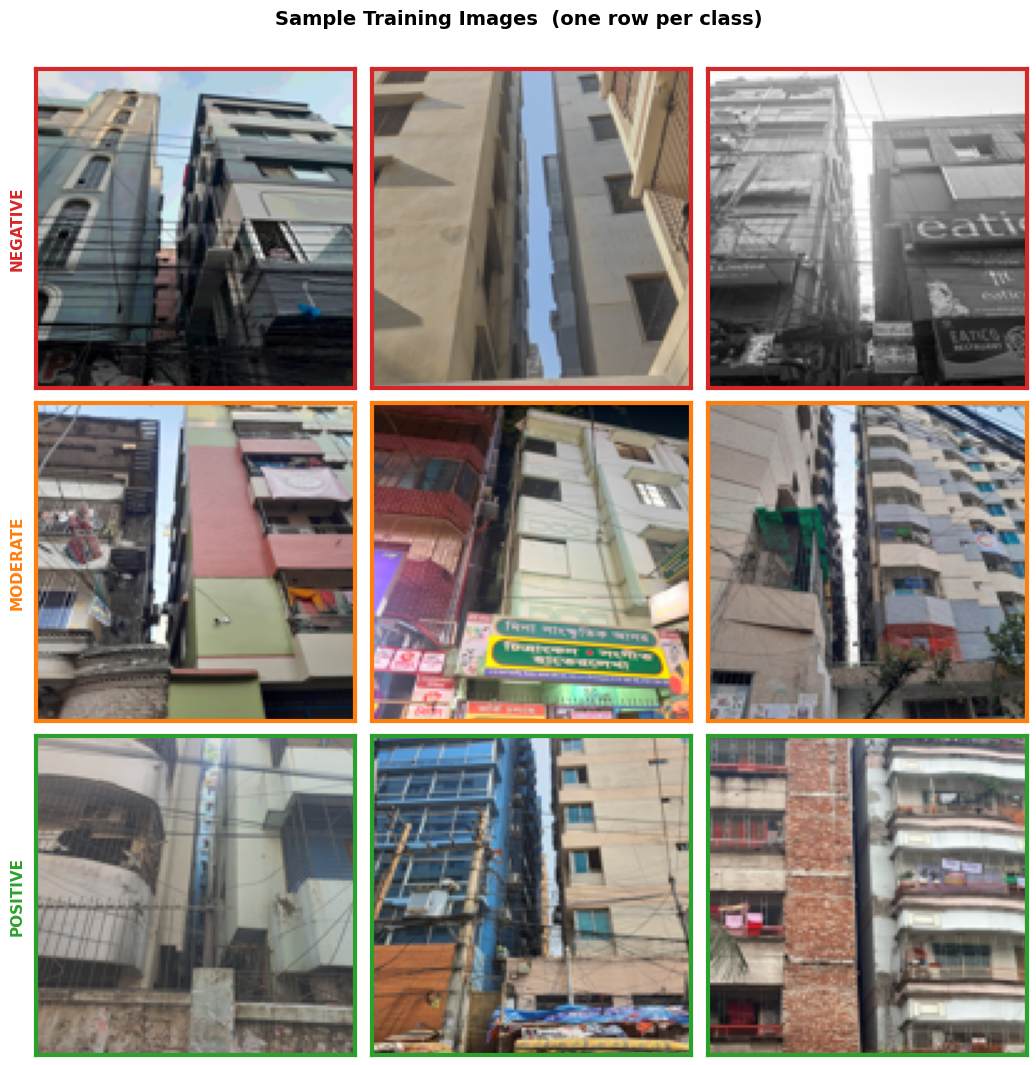

Sample images displayed.


In [6]:
# Show 3 random examples per class (9 images total)
SAMPLES_PER_CLASS = 3
label_to_paths = {i: [] for i in range(len(CLASS_NAMES))}
for p, lbl in zip(all_paths, all_labels):
    label_to_paths[lbl].append(p)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    len(CLASS_NAMES), SAMPLES_PER_CLASS,
    figsize=(SAMPLES_PER_CLASS * 3.5, len(CLASS_NAMES) * 3.5)
)
fig.suptitle('Sample Training Images  (one row per class)', fontsize=14, fontweight='bold', y=1.01)

# Colour-code borders per class
border_colours = ['#d62728', '#ff7f0e', '#2ca02c']   # red / orange / green

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    candidates = label_to_paths[cls_idx]
    chosen = rng.choice(len(candidates),
                        size=min(SAMPLES_PER_CLASS, len(candidates)),
                        replace=False)
    for col, path_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        img = Image.open(candidates[path_idx]).convert('RGB').resize(IMAGE_SIZE)
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_colours[cls_idx])
            spine.set_linewidth(3)
        if col == 0:
            ax.set_ylabel(cls_name.upper(), fontsize=11, fontweight='bold',
                          color=border_colours[cls_idx], rotation=90, labelpad=8)

plt.tight_layout()
plt.savefig('sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sample images displayed.')

## 7. Build Dataset & Pre-load into RAM

In [7]:
class RajukDataset(Dataset):
    """Pre-loads all images into RAM as float32 tensors to avoid slow Drive I/O."""

    def __init__(self, image_paths, labels, image_size):
        self.labels = torch.tensor(labels, dtype=torch.long)
        print(f'Pre-loading {len(image_paths):,} images into RAM …')
        tensors = []
        for p in image_paths:
            with Image.open(p) as img:
                arr = np.asarray(
                    img.convert('RGB').resize(image_size),
                    dtype=np.float32
                ) / 255.0
            tensors.append(torch.from_numpy(arr).permute(2, 0, 1))
        self.tensors = torch.stack(tensors)
        print('Pre-loading complete.')

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.tensors[idx], self.labels[idx]


if len(all_paths) == 0:
    raise ValueError('No labeled images found. Check your folder paths and label mapping.')

full_dataset = RajukDataset(all_paths, all_labels, IMAGE_SIZE)
N = len(full_dataset)
print(f'\nTotal samples in full dataset: {N:,}')

Pre-loading 2,720 images into RAM …
Pre-loading complete.

Total samples in full dataset: 2,720


## 8. Three-Way Split  (Train / Validation / Test)

| Split | Fraction | Purpose |
|-------|----------|---------|
| **Train** | 70 % | Model optimisation |
| **Validation** | 15 % | Hyper-parameter tuning & early stopping |
| **Test** | 15 % | Final unbiased evaluation |

> The test split is held out completely and **never used during training or validation**.

In [8]:
indices = np.arange(N)
y       = np.array(all_labels, dtype=np.int64)

# ── Step 1: carve out 15 % test set ──────────────────────────────────────────
trainval_idx, test_idx = train_test_split(
    indices, test_size=0.15, random_state=SEED, stratify=y
)

# ── Step 2: split remaining 85 % into train (70/85) and val (15/85) ──────────
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.15 / 0.85,   # ≈ 17.6 %  →  15 % of total
    random_state=SEED,
    stratify=y[trainval_idx]
)

print(f'Train      : {len(train_idx):>6,}  ({100*len(train_idx)/N:.1f} %)')
print(f'Validation : {len(val_idx):>6,}  ({100*len(val_idx)/N:.1f} %)')
print(f'Test       : {len(test_idx):>6,}  ({100*len(test_idx)/N:.1f} %)')

pin = torch.cuda.is_available()
NW  = 2

train_loader = DataLoader(Subset(full_dataset, train_idx),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NW, pin_memory=pin)
val_loader   = DataLoader(Subset(full_dataset, val_idx),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)
test_loader  = DataLoader(Subset(full_dataset, test_idx),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)

Train      :  1,904  (70.0 %)
Validation :    408  (15.0 %)
Test       :    408  (15.0 %)


## 9. CNN Architecture

In [9]:
class RajukCNN(nn.Module):
    """
    Small CNN for 128×128 RGB images.

    Block layout
    ─────────────────────────────────────────────
    Conv(3→32)  + BN + ReLU + MaxPool  → 64×64
    Conv(32→64) + BN + ReLU + MaxPool  → 32×32
    Conv(64→128)+ BN + ReLU + MaxPool  → 16×16
    Flatten → FC(32768→512) + BN + ReLU + Dropout
    FC(512→num_classes)
    """

    def __init__(self, num_classes: int, dropout: float = 0.5):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3,   32,  3, padding=1), nn.BatchNorm2d(32),  nn.ReLU(inplace=True), nn.MaxPool2d(2),
            # Block 2
            nn.Conv2d(32,  64,  3, padding=1), nn.BatchNorm2d(64),  nn.ReLU(inplace=True), nn.MaxPool2d(2),
            # Block 3
            nn.Conv2d(64,  128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Quick parameter count
_tmp = RajukCNN(len(CLASS_NAMES))
total_params = sum(p.numel() for p in _tmp.parameters())
print(f'Total parameters: {total_params:,}')
del _tmp

Total parameters: 16,873,987


## 10. Training & Evaluation Helpers

In [10]:
criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = correct = total = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss   = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total      += X.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_true = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss   = criterion(logits, y)
        total_loss += loss.item() * X.size(0)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total   += X.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_true


def make_model():
    m   = RajukCNN(len(CLASS_NAMES)).to(device)
    opt = optim.Adam(m.parameters(), lr=LR)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=3)
    return m, opt, sch


print('Helper functions defined.')

Helper functions defined.


## 11. K-Fold Cross-Validation on Train Split

In [11]:
train_labels_arr = y[train_idx]
min_cls = np.min(np.bincount(train_labels_arr, minlength=len(CLASS_NAMES)))
k = min(KFOLD_SPLITS, int(min_cls))
kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)

fold_val_accs = []
best_global_acc   = -1.0
best_global_state = None

for fold, (tr, va) in enumerate(kfold.split(train_idx, train_labels_arr)):
    print(f'\n{'─'*55}')
    print(f'  Fold {fold+1}/{k}   |   train={len(tr):,}   val={len(va):,}')
    print(f'{'─'*55}')

    fold_train_loader = DataLoader(
        Subset(full_dataset, train_idx[tr]),
        batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NW, pin_memory=pin
    )
    fold_val_loader = DataLoader(
        Subset(full_dataset, train_idx[va]),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NW, pin_memory=pin
    )

    model, optimizer, scheduler = make_model()
    best_fold_acc   = -1.0
    best_fold_state = None
    patience_ctr    = 0

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, fold_train_loader, optimizer)
        vl_loss, vl_acc, _, _ = evaluate(model, fold_val_loader)
        scheduler.step(vl_loss)

        print(f'  Ep {epoch+1:02d}/{NUM_EPOCHS}  '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.4f}  |  '
              f'Val   Loss={vl_loss:.4f} Acc={vl_acc:.4f}')

        if vl_acc > best_fold_acc:
            best_fold_acc   = vl_acc
            patience_ctr    = 0
            best_fold_state = {k2: v.cpu() for k2, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'  Early stopping at epoch {epoch+1}.')
                break

    fold_val_accs.append(best_fold_acc)
    print(f'  → Fold {fold+1} best val acc: {best_fold_acc:.4f}')

    if best_fold_acc > best_global_acc:
        best_global_acc   = best_fold_acc
        best_global_state = best_fold_state

print(f'\nCross-val accuracies : {[f"{a:.4f}" for a in fold_val_accs]}')
print(f'Mean CV accuracy     : {np.mean(fold_val_accs):.4f} ± {np.std(fold_val_accs):.4f}')


───────────────────────────────────────────────────────
  Fold 1/5   |   train=1,523   val=381
───────────────────────────────────────────────────────
  Ep 01/15  Train Loss=0.3151 Acc=0.8903  |  Val   Loss=0.0883 Acc=0.9816
  Ep 02/15  Train Loss=0.0397 Acc=0.9908  |  Val   Loss=0.0215 Acc=0.9895
  Ep 03/15  Train Loss=0.0170 Acc=0.9941  |  Val   Loss=0.0276 Acc=0.9895
  Ep 04/15  Train Loss=0.0161 Acc=0.9928  |  Val   Loss=0.0379 Acc=0.9895
  Ep 05/15  Train Loss=0.0231 Acc=0.9921  |  Val   Loss=0.0265 Acc=0.9895
  Ep 06/15  Train Loss=0.0170 Acc=0.9928  |  Val   Loss=0.0181 Acc=0.9895
  Ep 07/15  Train Loss=0.0146 Acc=0.9915  |  Val   Loss=0.0072 Acc=1.0000
  Ep 08/15  Train Loss=0.0112 Acc=0.9947  |  Val   Loss=0.0340 Acc=0.9816
  Ep 09/15  Train Loss=0.0132 Acc=0.9941  |  Val   Loss=0.0108 Acc=0.9895
  Ep 10/15  Train Loss=0.0087 Acc=0.9967  |  Val   Loss=0.0141 Acc=0.9895
  Ep 11/15  Train Loss=0.0168 Acc=0.9921  |  Val   Loss=0.0123 Acc=0.9895
  Ep 12/15  Train Loss=0.0132 Acc=

## 12. Fine-tune Best Model on Full Train Set, Then Evaluate on Val + Test

In [12]:
# Restore best cross-val weights
final_model = RajukCNN(len(CLASS_NAMES)).to(device)
final_model.load_state_dict({k: v.to(device) for k, v in best_global_state.items()})

# Fine-tune 5 more epochs on the full train split (no val used here)
ft_optimizer = optim.Adam(final_model.parameters(), lr=LR / 5)
print('Fine-tuning on full training split …')
for epoch in range(5):
    t_loss, t_acc = train_one_epoch(final_model, train_loader, ft_optimizer)
    print(f'  FT Epoch {epoch+1}/5  Loss={t_loss:.4f}  Acc={t_acc:.4f}')

# ── Validation results ────────────────────────────────────────────────────────
val_loss,  val_acc,  val_preds,  val_true  = evaluate(final_model, val_loader)
# ── Test results ──────────────────────────────────────────────────────────────
test_loss, test_acc, test_preds, test_true = evaluate(final_model, test_loader)

print(f'\n{'='*50}')
print(f'  Validation — Loss: {val_loss:.4f}   Acc: {val_acc:.4f}')
print(f'  Test       — Loss: {test_loss:.4f}   Acc: {test_acc:.4f}')
print(f'{'='*50}')

Fine-tuning on full training split …
  FT Epoch 1/5  Loss=0.0168  Acc=0.9926
  FT Epoch 2/5  Loss=0.0119  Acc=0.9947
  FT Epoch 3/5  Loss=0.0147  Acc=0.9942
  FT Epoch 4/5  Loss=0.0166  Acc=0.9916
  FT Epoch 5/5  Loss=0.0145  Acc=0.9942

  Validation — Loss: 0.0096   Acc: 0.9926
  Test       — Loss: 0.0148   Acc: 0.9926


## 13. Classification Report & Confusion Matrix

Test Set — Classification Report
──────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       1.00      0.99      0.99       224
    moderate       0.97      1.00      0.99       105
    positive       1.00      1.00      1.00        79

    accuracy                           0.99       408
   macro avg       0.99      1.00      0.99       408
weighted avg       0.99      0.99      0.99       408



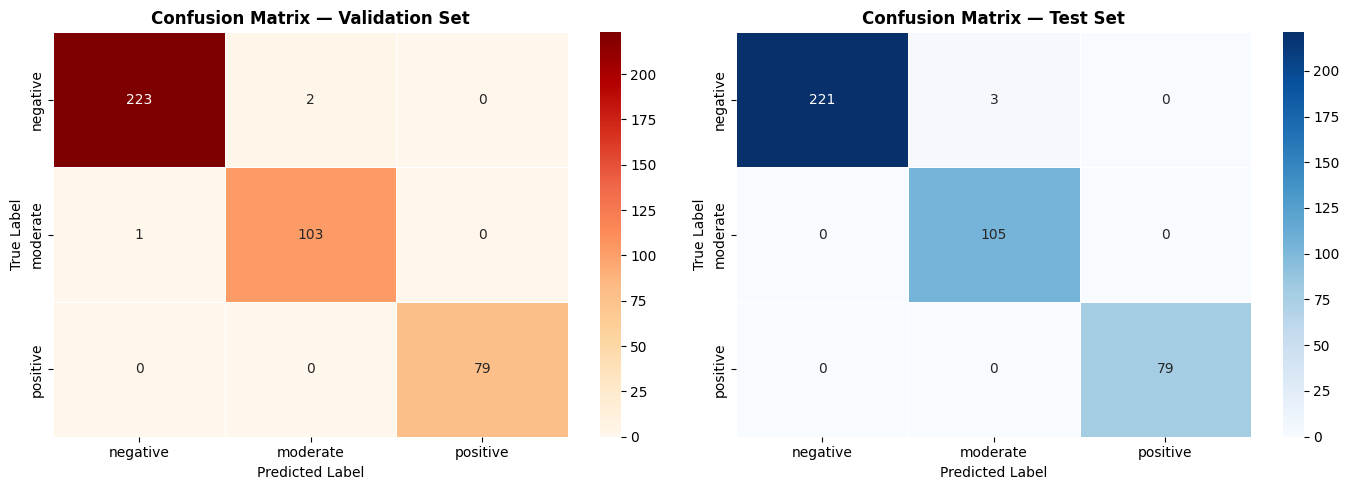

In [13]:
print('Test Set — Classification Report')
print('─' * 50)
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (preds, true, title, cmap) in zip(
    axes,
    [
        (val_preds,  val_true,  'Confusion Matrix — Validation Set', 'OrRd'),
        (test_preds, test_true, 'Confusion Matrix — Test Set',       'Blues'),
    ]
):
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 14. Learning Curves — Error vs. Dataset Size

For each dataset size in `DATASET_STEPS` we train a fresh model from scratch and measure **three errors**:

| Marker | Meaning |
|--------|---------|
| 🔵 Blue circle | **Training error** |
| 🟠 Orange triangle | **Validation error** |
| 🟢 Green square | **Test error** |

A well-generalising model should show decreasing gaps between the three curves as data grows.

In [14]:
def error_rate(loss):   # convert loss to a 0-1 error for plotting; alternatively 1-acc is clearer
    return loss


def train_and_measure(n_train: int):
    """
    Train a fresh model on `n_train` samples (stratified subset of train_idx)
    for a fixed number of epochs and return (train_loss, val_loss, test_loss).
    """
    # Stratified sub-sample of the training split
    actual_n = min(n_train, len(train_idx))
    if actual_n < len(CLASS_NAMES):   # too few to stratify
        return None

    sub_idx, _ = train_test_split(
        train_idx,
        train_size=actual_n,
        random_state=SEED,
        stratify=y[train_idx]
    )

    sub_loader = DataLoader(
        Subset(full_dataset, sub_idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )

    m, opt, sch = make_model()
    CURVE_EPOCHS = min(10, NUM_EPOCHS)   # fewer epochs keeps this fast

    for _ in range(CURVE_EPOCHS):
        train_one_epoch(m, sub_loader, opt)
        vl, _, _, _ = evaluate(m, val_loader)
        sch.step(vl)

    tr_loss, _, _, _ = evaluate(m, sub_loader)
    vl_loss, _, _, _ = evaluate(m, val_loader)
    te_loss, _, _, _ = evaluate(m, test_loader)
    return tr_loss, vl_loss, te_loss


# ── Run the experiment ────────────────────────────────────────────────────────
curve_sizes, curve_train, curve_val, curve_test = [], [], [], []

for n in DATASET_STEPS:
    if n > len(train_idx):
        print(f'  n={n}: exceeds train size ({len(train_idx)}), skipping.')
        break
    print(f'  Training on n={n} …', end=' ', flush=True)
    result = train_and_measure(n)
    if result is None:
        print('skipped (too few samples).')
        continue
    tr_l, vl_l, te_l = result
    curve_sizes.append(n)
    curve_train.append(tr_l)
    curve_val.append(vl_l)
    curve_test.append(te_l)
    print(f'train={tr_l:.4f}  val={vl_l:.4f}  test={te_l:.4f}')

print('\nLearning-curve data collected.')

  Training on n=100 … train=0.2386  val=0.6832  test=0.6929
  Training on n=200 … train=0.0268  val=0.3282  test=0.3609
  Training on n=300 … train=0.0164  val=0.2222  test=0.2679
  Training on n=400 … train=0.0092  val=0.0838  test=0.0829
  Training on n=500 … train=0.0139  val=0.0336  test=0.0332
  Training on n=600 … train=0.0127  val=0.0288  test=0.0314
  Training on n=700 … train=0.0147  val=0.0140  test=0.0197
  Training on n=800 … train=0.0161  val=0.0077  test=0.0172
  Training on n=900 … train=0.0162  val=0.0166  test=0.0206
  Training on n=1000 … train=0.0147  val=0.0084  test=0.0166

Learning-curve data collected.


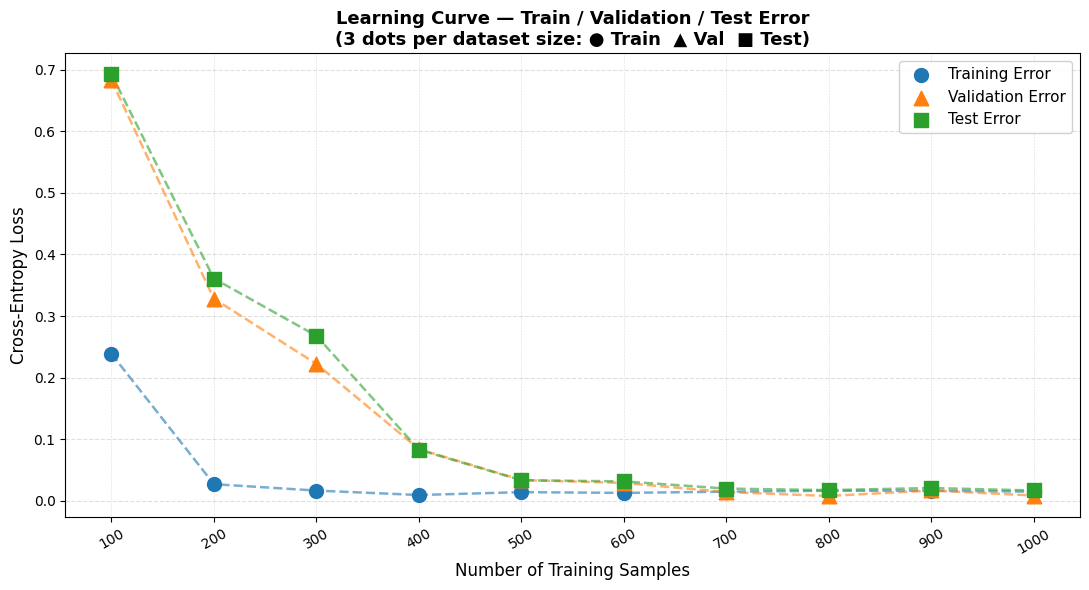

Learning curve saved.


In [15]:
# ── Plot: 3 dots per dataset size ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6))

# ── Lines (connect the dots) ──────────────────────────────────────────────────
ax.plot(curve_sizes, curve_train, color='#1f77b4', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_val,   color='#ff7f0e', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_test,  color='#2ca02c', linewidth=1.8, linestyle='--', alpha=0.6)

# ── Scatter dots (the 3 dots per size) ───────────────────────────────────────
ax.scatter(curve_sizes, curve_train, marker='o', s=100,
           color='#1f77b4', zorder=5, label='Training Error')
ax.scatter(curve_sizes, curve_val,   marker='^', s=110,
           color='#ff7f0e', zorder=5, label='Validation Error')
ax.scatter(curve_sizes, curve_test,  marker='s', s=100,
           color='#2ca02c', zorder=5, label='Test Error')

# ── Vertical grid lines per dataset step (group visual) ──────────────────────
for s in curve_sizes:
    ax.axvline(s, color='grey', linewidth=0.4, linestyle=':', alpha=0.5)

ax.set_xlabel('Number of Training Samples', fontsize=12)
ax.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax.set_title('Learning Curve — Train / Validation / Test Error\n'
             '(3 dots per dataset size: ● Train  ▲ Val  ■ Test)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.set_xticks(curve_sizes)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('learning_curve.png', dpi=130, bbox_inches='tight')
plt.show()
print('Learning curve saved.')

## 15. Full Training History (Final Model)

In [16]:
# Train a fresh model end-to-end and record per-epoch metrics
history_model, history_opt, history_sch = make_model()
h = {'train_loss': [], 'val_loss': [], 'test_loss': [],
     'train_acc':  [], 'val_acc':  [], 'test_acc':  []}

best_acc_ht   = -1.0
best_state_ht = None
patience_ht   = 0

print(f'Training for {NUM_EPOCHS} epochs …\n')
for epoch in range(NUM_EPOCHS):
    tr_l, tr_a = train_one_epoch(history_model, train_loader, history_opt)
    vl_l, vl_a, _, _ = evaluate(history_model, val_loader)
    te_l, te_a, _, _ = evaluate(history_model, test_loader)
    history_sch.step(vl_l)

    for key, val in zip(
        ['train_loss','val_loss','test_loss','train_acc','val_acc','test_acc'],
        [tr_l, vl_l, te_l, tr_a, vl_a, te_a]
    ):
        h[key].append(val)

    print(f'Ep {epoch+1:02d}/{NUM_EPOCHS}  '
          f'Train L={tr_l:.4f} A={tr_a:.4f} | '
          f'Val L={vl_l:.4f} A={vl_a:.4f} | '
          f'Test L={te_l:.4f} A={te_a:.4f}')

    if vl_a > best_acc_ht:
        best_acc_ht   = vl_a
        patience_ht   = 0
        best_state_ht = {k2: v.cpu() for k2, v in history_model.state_dict().items()}
    else:
        patience_ht += 1
        if patience_ht >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}.')
            break

print(f'\nBest validation accuracy: {best_acc_ht:.4f}')

Training for 15 epochs …

Ep 01/15  Train L=0.3028 A=0.8986 | Val L=0.0527 A=0.9877 | Test L=0.0704 A=0.9853
Ep 02/15  Train L=0.0378 A=0.9926 | Val L=0.0124 A=0.9926 | Test L=0.0180 A=0.9926
Ep 03/15  Train L=0.0199 A=0.9937 | Val L=0.0254 A=0.9951 | Test L=0.0383 A=0.9926
Ep 04/15  Train L=0.0251 A=0.9916 | Val L=0.0078 A=0.9926 | Test L=0.0154 A=0.9926
Ep 05/15  Train L=0.0162 A=0.9947 | Val L=0.0104 A=0.9975 | Test L=0.0266 A=0.9926
Ep 06/15  Train L=0.0184 A=0.9926 | Val L=0.0085 A=0.9951 | Test L=0.0159 A=0.9926
Ep 07/15  Train L=0.0204 A=0.9932 | Val L=0.0086 A=0.9951 | Test L=0.0158 A=0.9926
Ep 08/15  Train L=0.0153 A=0.9926 | Val L=0.0085 A=0.9926 | Test L=0.0150 A=0.9926
Ep 09/15  Train L=0.0161 A=0.9916 | Val L=0.0095 A=0.9951 | Test L=0.0160 A=0.9926
Ep 10/15  Train L=0.0128 A=0.9937 | Val L=0.0074 A=0.9926 | Test L=0.0132 A=0.9902
Early stopping at epoch 10.

Best validation accuracy: 0.9975


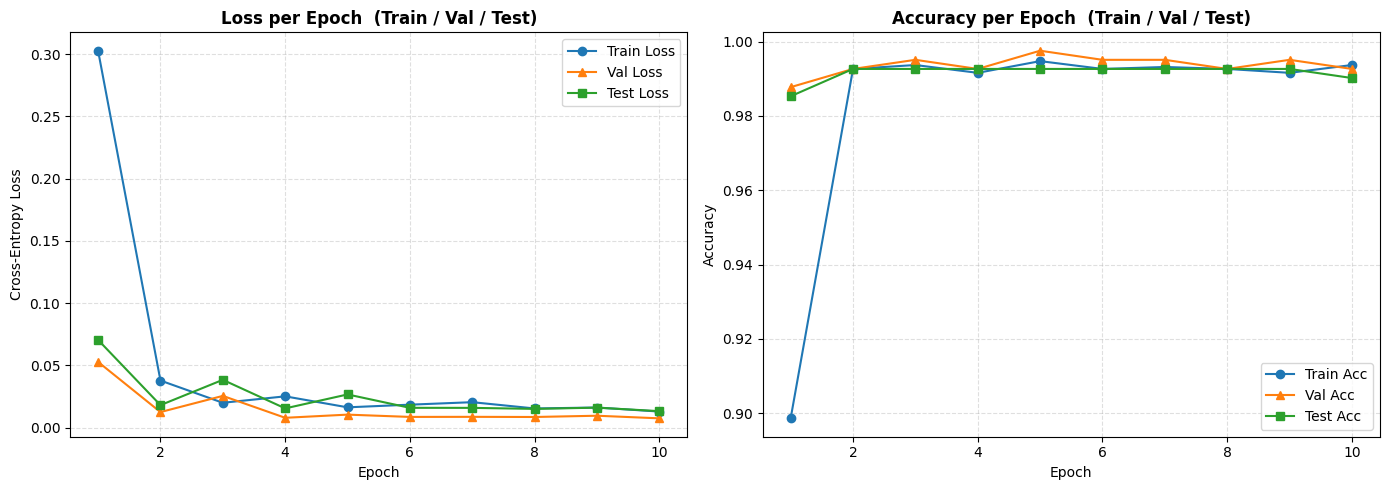

In [17]:
epochs_ran = range(1, len(h['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ── Loss ──────────────────────────────────────────────────────────────────────
ax1.plot(epochs_ran, h['train_loss'], 'o-', color='#1f77b4', label='Train Loss')
ax1.plot(epochs_ran, h['val_loss'],   '^-', color='#ff7f0e', label='Val Loss')
ax1.plot(epochs_ran, h['test_loss'],  's-', color='#2ca02c', label='Test Loss')
ax1.set_title('Loss per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(); ax1.grid(linestyle='--', alpha=0.4)

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax2.plot(epochs_ran, h['train_acc'], 'o-', color='#1f77b4', label='Train Acc')
ax2.plot(epochs_ran, h['val_acc'],   '^-', color='#ff7f0e', label='Val Acc')
ax2.plot(epochs_ran, h['test_acc'],  's-', color='#2ca02c', label='Test Acc')
ax2.set_title('Accuracy per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend(); ax2.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('training_history.png', dpi=130, bbox_inches='tight')
plt.show()

## 16. Save Model Artifact

In [18]:
save_path = DRIVE_BASE / 'rajuk_cnn.pth'

artifact = {
    'model_state_dict' : best_state_ht,
    'class_names'      : CLASS_NAMES,
    'image_size'       : IMAGE_SIZE,
    'label_source'     : str(source_path),
    'label_column'     : level_col,
    'best_val_acc'     : best_acc_ht,
    'kfold_val_accs'   : fold_val_accs,
    'train_size'       : len(train_idx),
    'val_size'         : len(val_idx),
    'test_size'        : len(test_idx),
    'final_test_acc'   : test_acc,
}

torch.save(artifact, save_path)
print(f'Model saved to: {save_path}')
print(f'Final test accuracy : {test_acc:.4f}')

Model saved to: /content/drive/MyDrive/ML_Project/rajuk_cnn.pth
Final test accuracy : 0.9926


## 17. Sanity Check — Predict on a Few Samples

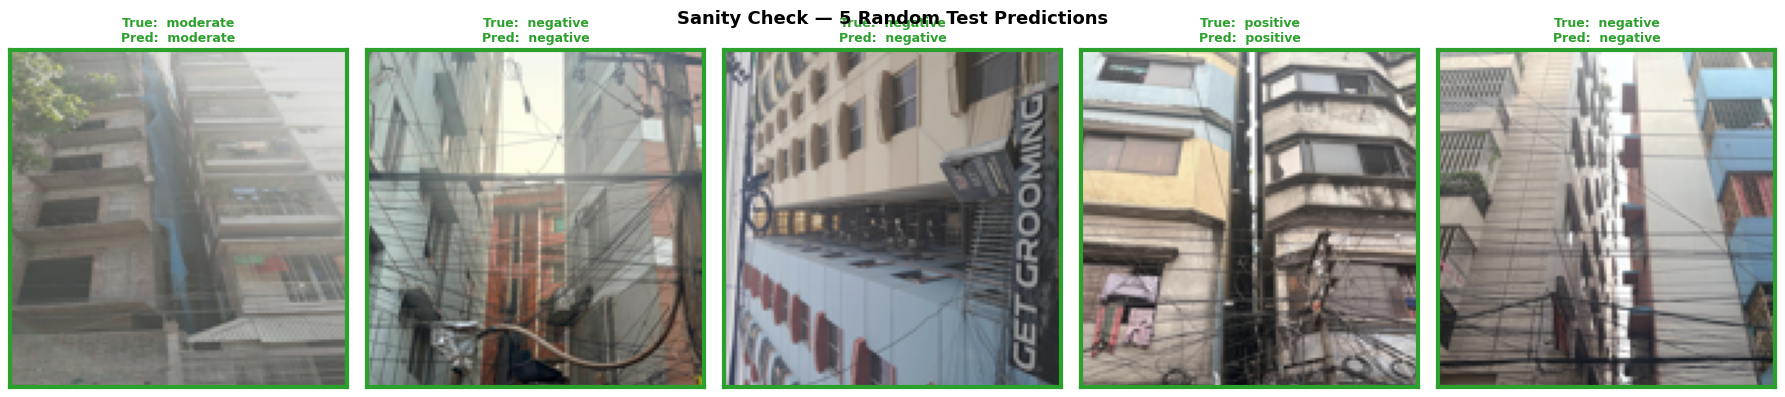

Sanity check complete.


In [19]:
best_model = RajukCNN(len(CLASS_NAMES)).to(device)
best_model.load_state_dict({k: v.to(device) for k, v in best_state_ht.items()})
best_model.eval()

# Show 5 random test images with their predicted and true labels
rng2   = np.random.default_rng(SEED + 1)
sample = rng2.choice(len(test_idx), size=5, replace=False)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
fig.suptitle('Sanity Check — 5 Random Test Predictions', fontsize=13, fontweight='bold')

with torch.no_grad():
    for ax, s_idx in zip(axes, sample):
        img_tensor, true_lbl = full_dataset[test_idx[s_idx]]
        logits  = best_model(img_tensor.unsqueeze(0).to(device))
        pred_lbl = logits.argmax(1).item()

        img_np = img_tensor.permute(1, 2, 0).numpy()
        ax.imshow(img_np)
        ax.set_xticks([]); ax.set_yticks([])

        colour = '#2ca02c' if pred_lbl == true_lbl else '#d62728'
        ax.set_title(
            f'True:  {CLASS_NAMES[true_lbl]}\nPred:  {CLASS_NAMES[pred_lbl]}',
            fontsize=9, color=colour, fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor(colour); spine.set_linewidth(3)

plt.tight_layout()
plt.savefig('sanity_predictions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sanity check complete.')